# Exploración por MCMC del a posteriori de los escalares del motor: un pliegue corrido en vivo, su cadena, su tiempo de autocorrelación y lo que una corrida corta puede y no puede decir

**Pregunta:** ¿Qué hace el muestreador de la calibración bayesiana sobre un muestreo retenido cuando se corre en vivo con una cadena corta, cuánto dura su tiempo de autocorrelación, y qué puede decir una cadena tan corta de los escalares que informa el documento versionado?

- **Nivel:** 2, el método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 60 minutos (las dos corridas en vivo toman de dos a tres minutos en total)

## Objetivos

Al terminar este notebook usted puede:

- enunciar la verosimilitud de la calibración, con la discrepancia integrada, y decir qué explora el muestreador y qué sortea después;
- correr en vivo el muestreador del pipeline sobre un pliegue y leer sus diagnósticos: aceptación, tiempo de autocorrelación integrado y largo de la cadena medido en tiempos de autocorrelación;
- dibujar las cadenas de dos parámetros y decir cómo se ve una traza que no ha olvidado su inicio;
- decir qué números de este notebook son en vivo y cortos y cuáles son los versionados de largo completo, y por qué los primeros no pueden reemplazar a los segundos.

## Preparación

Numpy y matplotlib, y `emcee` (Foreman-Mackey et al., 2013), el muestreador de conjunto que llama el módulo CrusherBayes del pipeline. El notebook lo llama directamente una vez, por su estimador de autocorrelación en la sección sobre el largo de la cadena; el pin está aquí porque las corridas en vivo lo necesitan instalado.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 emcee==3.1.6
```

Las importaciones traen el lector de muestreos, el módulo CrusherBayes (su configuración, a priori y ejecutor de pliegues), las funciones de CrusherCal y el motor.

In [1]:

# Imprima las versiones de las herramientas de este notebook, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from emcee import autocorr

for name in ('numpy', 'matplotlib', 'emcee'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import crusherbayes as cb, loo
from pipeline.model.crusher import evaluate, operating_from_survey
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2
emcee 3.1.6


## Datos

Los diez muestreos del HP500. Propietarios: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las filas están transcritas de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, y `data/derived/hp500/crusherbayes.json`, el documento que escribió el cálculo fuera de línea con las cadenas de largo completo; aquí se lee solo para decir qué números son los versionados.

La celda lee ambos archivos e imprime el tamaño de las cadenas versionadas.

In [2]:

# Los muestreos, y el documento versionado del cálculo completo, leído solo para decir qué números son
# cuáles
surveys = read_surveys().accepted
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
tph = np.array([s.feed_tph for s in surveys])
kw = np.array([s.power_kw for s in surveys])
ops = [operating_from_survey(c, f) for c, f in zip(css, f80)]
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
meth = committed["method"]
text = (
    'documento versionado: {} pasos por cadena, {} caminantes, '
    'calentamiento {}, raleo {}'
)
print(text.format(meth["steps"], meth["walkers"], meth["burn_in_steps"], meth["thin"]))


documento versionado: 7000 pasos por cadena, 20 caminantes, calentamiento 1000, raleo 10


## Método

**El modelo.** Para el muestreo $i$ y el objetivo $t$ (tonelaje o potencia) el valor medido es el motor con los escalares $\theta$ más una discrepancia lineal en la abertura y el f80 estandarizados, más ruido gaussiano:

$$y_{t,i} = f_t(\theta; \mathrm{CSS}_i, f_{80,i}) + d_{t0} + d_{t1} z_{\mathrm{CSS},i} + d_{t2} z_{f_{80},i} + \varepsilon_{t,i}, \qquad d_{tj} \sim N(0, \tau_t^2),\ \varepsilon \sim N(0, \sigma_t^2).$$

Como los coeficientes de la discrepancia y el ruido son gaussianos dado $\theta$, se pueden integrar de forma exacta: el vector de residuos $y_t - f_t(\theta)$ es entonces normal con covarianza $\sigma_t^2 I + \tau_t^2 Z Z^{\top}$, y el muestreador solo explora los ocho escalares del motor y las dos escalas de ruido, diez dimensiones. Los coeficientes $d$ se sortean después de su condicional gaussiana exacta dado cada $\theta$ retenido. El muestreador es el conjunto de 20 caminantes de `emcee` con movimientos de evolución diferencial (ter Braak, 2006), el 80 por ciento de las propuestas, y su variante snooker (ter Braak y Vrugt, 2008), el 20 por ciento: un caminante salta a lo largo de la diferencia entre otros dos, lo que adapta el paso a la forma del a posteriori y no necesita gradiente, como exige un motor llamado como caja negra. Una elección anterior, el movimiento de estiramiento invariante afín de Goodman y Weare (2010), dejó el tiempo de autocorrelación sobre 100 pasos y creciendo, y ningún a posteriori alcanzó el diagnóstico; los movimientos de evolución diferencial son lo que hizo converger las cadenas versionadas.

**Correr un pliegue.** Un pliegue retiene un muestreo: el a posteriori se ajusta con los otros nueve y el muestreo retenido entra solo en la predicción, un sorteo del motor en cada $\theta$ retenido más la discrepancia y el ruido. El documento versionado corre 7000 pasos por cadena para cada uno de los diez pliegues y para el ajuste con los diez. Un notebook no puede permitirse eso, así que la celda corre un pliegue, el muestreo 4, con 200 pasos, 60 de ellos de calentamiento, con la misma función que usa el cálculo (`fit_inline`); los diagnósticos que imprime son los del propio muestreador.

In [3]:

# Un pliegue en vivo: el muestreo 4 retenido (índice 3), una cadena reducida, el muestreador del pipeline
HELD = 3
spec = {"css": css.tolist(), "f80": f80.tolist(), "tph": tph.tolist(), "kW": kw.tolist(), "held": HELD, "seed": 42}
live_cfg = cb.Config(walkers=20, steps=200, burn=60, thin=4, draws=10)
fold = cb.fit_inline(dict(spec, config=live_cfg.__dict__))
print(f"pliegue en vivo, {live_cfg.steps} pasos ({fold['post_burn_steps']} tras el calentamiento): "
      f"convergió {fold['converged']}, tau {fold['tau_max']:.1f} pasos, "
      f"cadena sobre tau {fold['ratio']:.1f}, aceptación {fold['acceptance']:.2f}")
for name, y in (("tph", tph), ("kW", kw)):
    p = fold["pred"][name]
    print(f"{name:5s} media en vivo {p['mean']:7.1f}, intervalo 80 % {p['lo80']:7.1f} a {p['hi80']:7.1f}, "
          f"medido {y[HELD]:7.1f}")


pliegue en vivo, 200 pasos (140 tras el calentamiento): convergió False, tau 11.8 pasos, cadena sobre tau 11.8, aceptación 0.28
tph   media en vivo  1194.1, intervalo 80 %   992.8 a  1388.0, medido  1034.0
kW    media en vivo   273.5, intervalo 80 %   235.3 a   312.7, medido   349.0


La cadena en vivo es corta a propósito: 200 pasos, 60 de ellos de calentamiento, frente a 7000 y 1000 en el documento versionado. Su propio diagnóstico da un tiempo de autocorrelación de 11,8 pasos, así que sus 140 pasos tras el calentamiento son 11,8 tiempos de autocorrelación según su propia cuenta, bajo los 50 que exige el pipeline, y la corrida se declara no convergida. Su intervalo predictivo para el muestreo 4 está sin embargo en la vecindad del versionado. La celda siguiente imprime el pliegue versionado del mismo muestreo y mide la cadena en vivo con el tiempo de autocorrelación versionado, que es lo que dice si se puede creer la estimación en vivo de 11,8 pasos.

El diagnóstico es el tiempo de autocorrelación integrado de la cadena, estimado con el estimador con ventana que implementa emcee (Foreman-Mackey et al., 2013), sobre cadenas de los muestreadores de conjunto de Goodman y Weare (2010) y ter Braak (2006), y la regla del pipeline para conservar una posterior:

$$\hat\tau = 1 + 2 \sum_{k=1}^{M} \hat\rho(k), \qquad N_{\mathrm{post}} \ge 50\, \max_j \hat\tau_j,$$

donde $\hat\rho(k)$ es la autocorrelación de la cadena de un parámetro con un rezago de $k$ pasos, promediada sobre los caminantes, $M$ la ventana más pequeña con $M \ge 5\hat\tau$, $\hat\tau_j$ la estimación para el parámetro $j$, y $N_{\mathrm{post}}$ el número de pasos después del calentamiento. Una cadena de $N$ pasos contiene cerca de $N / \hat\tau$ muestras independientes por caminante, así que la regla pide cincuenta de ellas; la trampa es que $\hat\tau$ se estima con la misma cadena. Este $\hat\tau$, y la palabra tau en las salidas impresas, es el tiempo de autocorrelación de una cadena en pasos del muestreador; no tiene relación con la escala de discrepancia $\tau_t$ del modelo de arriba, una desviación estándar a priori en las unidades del objetivo $t$.

In [4]:

# El pliegue versionado del mismo muestreo, corrido con el largo completo, junto al en vivo
folds = {c["fold"]: c for c in committed["convergence"]["folds"]}
doc = folds[HELD + 1]
print(f"pliegue versionado: convergió {doc['converged']}, tau {doc['tau_max']:.1f} pasos, "
      f"cadena sobre tau {doc['chain_over_tau']:.1f}, aceptación {doc['acceptance_fraction']:.2f}")
for name in ("tph", "kW"):
    block = committed["loo"][name]
    print(f"{name:5s} media versionada {block['pred_mean'][HELD]:7.1f}, intervalo 80 % {block['lo80'][HELD]:7.1f} a "
          f"{block['hi80'][HELD]:7.1f}")
# El tiempo de autocorrelación en vivo frente al versionado, y la cadena en vivo en taus versionados
print(f"tau versionado sobre tau en vivo: {doc['tau_max'] / fold['tau_max']:.1f}; "
      "la cadena en vivo tras el calentamiento mide "
      f"{fold['post_burn_steps'] / doc['tau_max']:.1f} tiempos de autocorrelación versionados")
# El registro completo de convergencia: cada a posteriori versionada, su cadena sobre tau y el pliegue más lento
record = committed["convergence"]["folds"]
ratios = [c["chain_over_tau"] for c in record]
slowest = max((c for c in record if c["fold"] != "all"), key=lambda c: c["tau_max"])
print(f"a posteriori convergidas: {sum(c['converged'] for c in record)} de {len(record)} | cadena sobre tau "
      f"{min(ratios):.1f} a {max(ratios):.1f}",
             f"| pliegue más lento: muestreo {slowest['fold']}, tau {slowest['tau_max']:.1f}")


pliegue versionado: convergió True, tau 84.8 pasos, cadena sobre tau 70.7, aceptación 0.17
tph   media versionada  1195.2, intervalo 80 %   999.5 a  1388.2
kW    media versionada   271.4, intervalo 80 %   233.7 a   310.1
tau versionado sobre tau en vivo: 7.2; la cadena en vivo tras el calentamiento mide 1.7 tiempos de autocorrelación versionados
a posteriori convergidas: 11 de 11 | cadena sobre tau 70.7 a 125.0 | pliegue más lento: muestreo 4, tau 84.8


Versionado, el pliegue del muestreo 4 tiene un tiempo de autocorrelación de 84,8 pasos, 7,2 veces los 11,8 pasos que la cadena en vivo midió para sí misma, y una cadena de 70,7 veces eso, sobre los 50 que pide el pipeline: las 11 distribuciones a posteriori versionadas pasan el diagnóstico, con cadena sobre tau entre 70,7 y 125,0. Medidos con el tiempo de autocorrelación versionado, los 140 pasos tras el calentamiento de la corrida en vivo son 1,7 tiempos de autocorrelación, no 11,8. Una cadena corta subestima su propio tiempo de autocorrelación, porque no ha corrido lo bastante para ver qué tan lento se descorrelaciona, y así favorece a su propio diagnóstico. El muestreo 4 es el más lento de los diez pliegues, como imprime el registro de convergencia, así que es el caso exigente para una corrida en vivo, y el diagnóstico versionado es la cifra confiable.

**Las cadenas.** Para ver las cadenas mismas el notebook necesita las muestras retenidas, que el pipeline devuelve para el ajuste con los diez muestreos y no para un pliegue, así que la celda siguiente corre brevemente ese ajuste (120 pasos), guarda sus muestras y lo mide de la misma forma frente al a posteriori versionado con los diez.

In [5]:

# El a posteriori con los diez muestreos, en vivo y corto, para ver la cadena de los escalares
all_cfg = cb.Config(walkers=20, steps=120, burn=40, thin=2, draws=10)
every = cb.fit_inline(dict(spec, held=None, config=all_cfg.__dict__))
chain = np.array(every["theta"])
print(f"corrida en vivo con los diez, {all_cfg.steps} pasos: tau {every['tau_max']:.1f} pasos, "
      f"cadena sobre tau {every['ratio']:.1f}, {chain.shape[0]} muestras retenidas")
# La misma cadena en vivo medida con el tiempo de autocorrelación versionado del ajuste con los diez
print(f"tau versionado con los diez: {folds['all']['tau_max']:.1f} pasos; "
      "la cadena en vivo tras el calentamiento mide "
      f"{every['post_burn_steps'] / folds['all']['tau_max']:.1f} tiempos de autocorrelación versionados")


corrida en vivo con los diez, 120 pasos: tau 7.9 pasos, cadena sobre tau 10.2, 800 muestras retenidas
tau versionado con los diez: 48.6 pasos; la cadena en vivo tras el calentamiento mide 1.6 tiempos de autocorrelación versionados


La corrida con los diez cuenta lo mismo: 10,2 tiempos de autocorrelación según su propia cuenta y 1,6 según la versionada. Las muestras retenidas vuelven planas, paso tras paso con los 20 caminantes de cada paso juntos; la celda las reordena por paso, caminante y parámetro.

In [6]:

# Reordenar las muestras retenidas en pasos por caminantes por parámetros, para dibujar las cadenas
walkers = all_cfg.walkers
steps_kept = chain.shape[0] // walkers
chains = chain.reshape(steps_kept, walkers, -1)
print(chains.shape)


(40, 20, 10)


La figura dibuja cinco de los 20 caminantes para la base de capacidad y para la escala de ruido de la potencia, en el orden retenido tras el calentamiento.

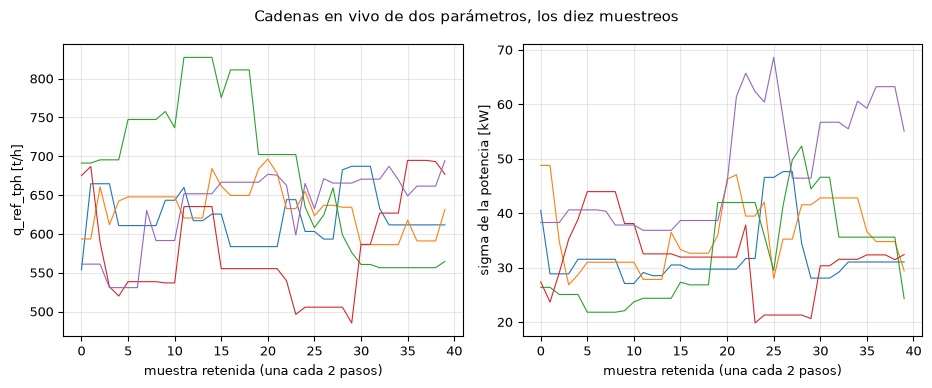

In [7]:

# Las cadenas de la base de capacidad y del ruido de potencia, cinco caminantes
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
panels = (
    (axes[0], 0, np.exp, 'q_ref_tph [t/h]'),
    (axes[1], cb.N_ENGINE + 1, np.exp, 'sigma de la potencia [kW]'),
)
for ax, column, transform, ylabel in panels:
    for w in range(5):
        ax.plot(transform(chains[:, w, column]), lw=0.8)
    ax.set_xlabel('muestra retenida (una cada {} pasos)'.format(all_cfg.thin))
    ax.set_ylabel(ylabel)
fig.suptitle('Cadenas en vivo de dos parámetros, los diez muestreos')
fig.tight_layout()
plt.show()


Una cadena convergida se ve como una banda sin deriva ni tramos visibles, en la que un caminante vuelve a visitar cada parte de la banda muchas veces. Estas trazas son un tramo corto desde cerca del centro del a priori, donde los caminantes parten en una bola pequeña: cada caminante todavía vaga lentamente en un rango del tamaño de la banda, que es como se ve una cadena de menos de dos tiempos de autocorrelación. La figura no muestra dónde se asientan las cadenas; las versionadas, de 7000 pasos, son las que se asientan, y su registro está abajo.

Lo que las muestras dicen de los parámetros es la contracción, la desviación estándar del a posteriori sobre la del a priori: cerca de 1 los datos no movieron el parámetro, muy por debajo de 1 sí. La celda la imprime para los ocho escalares con la cadena en vivo junto a la razón versionada del ajuste de largo completo, y pregunta si las dos columnas ordenan los escalares de la misma forma, con la correlación de rangos entre ambas.

In [8]:

# A posteriori frente a a priori en la corrida en vivo: media y desviación estándar de cada escalar,
# y la correlación de rangos entre la contracción en vivo y la versionada
contraction = {c["name"]: c["contraction"] for c in committed["contraction"]}
header = ('escalar          media a priori  sd a priori  media vivo  sd '
          'vivo  sd vivo / sd a priori   razón versionada')
print(header)
live_ratio = np.zeros(cb.N_ENGINE)
for i, p in enumerate(cb.PRIORS):
    live = np.exp(chain[:, i]) if p.log else chain[:, i]
    prior_sd = cb.prior_sd_natural(p)
    live_ratio[i] = live.std() / prior_sd
    print(f"{p.name:15s} {p.nominal:11.2f} {prior_sd:9.3f} {live.mean():11.3f} {live.std():8.3f}", end=" ")
    print(f"{live_ratio[i]:20.2f} {contraction[p.name]:18.2f}")
# Correlación de rangos de las dos columnas, con los ocho escalares y sin la base de capacidad
committed_ratio = np.array([contraction[p.name] for p in cb.PRIORS])
rank_live = np.argsort(np.argsort(live_ratio))
rank_committed = np.argsort(np.argsort(committed_ratio))
rho_all = np.corrcoef(rank_live, rank_committed)[0, 1]
rest_live = np.argsort(np.argsort(live_ratio[1:]))
rest_committed = np.argsort(np.argsort(committed_ratio[1:]))
rho_rest = np.corrcoef(rest_live, rest_committed)[0, 1]
print(f"correlación de rangos de las razones en vivo y versionadas: {rho_all:+.2f} con los ocho escalares, "
      f"{rho_rest:+.2f} sin q_ref_tph")


escalar          media a priori  sd a priori  media vivo  sd vivo  sd vivo / sd a priori   razón versionada
q_ref_tph            647.00   167.010     627.595   65.102                 0.39               0.45
wi_kwh_t               9.00     1.516       8.076    1.077                 0.71               0.85
zeta                   1.30     0.305       1.284    0.255                 0.84               0.73
pn_kw                110.00    47.853      77.200   36.365                 0.76               0.80
k1_scale               1.00     0.152       1.057    0.111                 0.73               0.96
k2_scale               1.00     0.152       1.087    0.108                 0.71               1.03
k3                     2.30     0.489       2.139    0.297                 0.61               0.99
t10_shift_pct          0.00     3.991       2.938    2.569                 0.64               0.99
correlación de rangos de las razones en vivo y versionadas: -0.24 con los ocho escalares, -0.86 sin 

La figura muestra el histograma en vivo de la base de capacidad con el centro de su a priori, y de la pendiente de discrepancia en la abertura para la potencia, con el cero marcado.

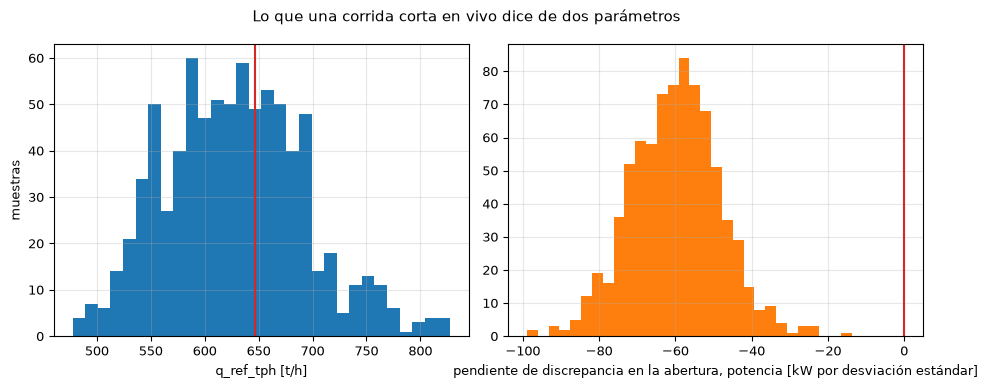

In [9]:

# Histograma de la base de capacidad y de una pendiente de discrepancia en la corrida en vivo, con el centro
# del a priori y el cero
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
axes[0].hist(np.exp(chain[:, 0]), bins=30, color="tab:blue")
axes[0].axvline(cb.PRIORS[0].nominal, color="tab:red", lw=1.5)
axes[0].set_xlabel('q_ref_tph [t/h]')
axes[0].set_ylabel('muestras')
slope = np.array(every["d_samples"]["kW"])[:, 1]
axes[1].hist(slope, bins=30, color="tab:orange")
axes[1].axvline(0.0, color="tab:red", lw=1.5)
axes[1].set_xlabel((
    'pendiente de discrepancia en la abertura, potencia [kW por '
    'desviación estándar]'
))
fig.suptitle('Lo que una corrida corta en vivo dice de dos parámetros')
fig.tight_layout()
plt.show()


Una cadena tan corta no puede ordenar los escalares, salvo la base de capacidad. La correlación de rangos entre las razones en vivo y las versionadas es -0,24 con los ocho escalares y -0,86 sin la base de capacidad, ambas negativas: `zeta` es el menos contraído en vivo (0,84) y el segundo más contraído en el ajuste versionado (0,73), y `k3` es el segundo más contraído en vivo (0,61) y queda en su a priori en el ajuste versionado (0,99). Todas las razones en vivo están entre 0,39 y 0,84, que es como se ven unos caminantes que partieron en una bola pequeña en torno al centro del a priori y todavía no terminan de extenderse: una razón en vivo bajo 1 refleja ese inicio, no información de los datos. Solo la base de capacidad, el único escalar que mueve el tonelaje (notebook 01), es la más contraída en ambas columnas (0,39 en vivo, 0,45 versionada). La columna versionada, de cadenas que pasaron su diagnóstico, es la que se cita: `k1_scale`, `k2_scale`, `k3` y `t10_shift_pct` quedan en 0,96, 1,03, 0,99 y 0,99, que es su a priori. La pendiente en la abertura para la potencia es negativa, con el cero fuera de la masa de su histograma: la discrepancia toma la caída de la potencia de la planta al abrirse la abertura que el motor no capta (notebook 01). Los histogramas vienen de la misma cadena corta, así que de ellos se puede leer el signo de la pendiente y no sus anchos.

**Qué hace el motor calibrado.** La media a posteriori de los escalares de la cadena en vivo se puede devolver al motor, que se evalúa en los diez muestreos, dentro de la muestra, con la función del propio motor. No es un resultado con retención y se rotula así: dice qué logran los escalares solos, sin la discrepancia.

In [10]:

# El motor con la media a posteriori en vivo de los escalares, en los diez muestreos, dentro de la
# muestra
theta_mean = chain.mean(axis=0)
calibrated = [evaluate(op, cb.scalars_of(theta_mean)) for op in ops]
cal_tph = np.array([r.throughput_tph for r in calibrated])
cal_kw = np.array([r.power_kw for r in calibrated])


El motor de fábrica se evalúa igual, y la celda imprime el error dentro de la muestra de ambos en los dos objetivos.

In [11]:

# El motor de fábrica sobre los mismos muestreos, y el error dentro de la muestra de los dos motores
# lado a lado
shipped = [evaluate(op) for op in ops]
ship_tph = np.array([r.throughput_tph for r in shipped])
ship_kw = np.array([r.power_kw for r in shipped])
text = (
    'motor con la media a posteriori dentro de la muestra: MAPE '
    '{:.2f} % en el tonelaje y {:.2f} % en la potencia; de fábrica '
    '{:.2f} % y {:.2f} %'
)
print(text.format(loo.mape(tph, cal_tph), loo.mape(kw, cal_kw),
                  loo.mape(tph, ship_tph), loo.mape(kw, ship_kw)))


motor con la media a posteriori dentro de la muestra: MAPE 12.55 % en el tonelaje y 24.43 % en la potencia; de fábrica 11.55 % y 47.58 %


Dentro de la muestra, el motor con la media a posteriori en vivo tiene un MAPE de potencia de 24,43 por ciento frente a 47,58 del motor de fábrica, cerca de la mitad, y un MAPE de tonelaje de 12,55 por ciento frente a 11,55, algo peor: los escalares quitan la mayor parte del desplazamiento de la potencia y ceden a cambio un poco de precisión en el tonelaje. La banda que CrusherCal da a un modelo a partir de sus residuos, `loo.predictive_band`, se puede poner alrededor de los residuos de potencia de los dos motores, para comparar cuánta dispersión deja cada uno.

In [12]:

# La banda de 80 por ciento dentro de la muestra de los residuos de potencia del motor calibrado, con
# la función de CrusherCal
cal_band = loo.predictive_band(kw - cal_kw)
ship_band = loo.predictive_band(kw - ship_kw)
text = (
    'motor calibrado, potencia: sigma {:.1f} kW, semiancho {:.1f} '
    'kW; motor de fábrica: sigma {:.1f} kW, semiancho {:.1f} kW'
)
print(text.format(cal_band["sigma"], cal_band["halfwidth"], ship_band["sigma"], ship_band["halfwidth"]))


motor calibrado, potencia: sigma 71.6 kW, semiancho 91.8 kW; motor de fábrica: sigma 73.5 kW, semiancho 94.2 kW


Los escalares casi no cambian la dispersión: el sigma de los residuos de potencia es 71,6 kW para el motor calibrado frente a 73,5 kW para el de fábrica, así que lo que la calibración quitó es el desplazamiento y no la dispersión a su alrededor. Los mismos residuos pueden recibir la cobertura anidada de CrusherCal, en la que la banda de cada muestreo la fijan los otros nueve, para ver si la calibración la cambia.

In [13]:

# La cobertura anidada de los residuos de potencia de los dos motores, con el sigma de cada muestreo
# tomado de los otros nueve
cal_nested = loo.nested_band_coverage(kw - cal_kw)
ship_nested = loo.nested_band_coverage(kw - ship_kw)
text = (
    'cobertura anidada de 80 % de la potencia: motor calibrado '
    '{:.2f}, motor de fábrica {:.2f}'
)
print(text.format(cal_nested["coverage"], ship_nested["coverage"]))


cobertura anidada de 80 % de la potencia: motor calibrado 0.70, motor de fábrica 0.60


La cobertura anidada de la potencia es 0,70 para el motor calibrado y 0,60 para el de fábrica, frente al 0,80 nominal. Con diez muestreos uno mueve la cobertura en 0,1, así que al motor calibrado le falta un muestreo para el valor nominal y al de fábrica dos: la calibración agrega un muestreo cubierto. Lo que falta se debe al desplazamiento y no al ancho: cada banda se dimensiona con la dispersión de los residuos en torno a su propia media pero se centra en cero, así que los muestreos que deja fuera son los que el desplazamiento empuja afuera. Por último, el motor puede correrse en sorteos a posteriori retenidos y no solo en su media: la dispersión de la potencia entre los sorteos es la parte de la incertidumbre que llevan los escalares, antes de la discrepancia y el ruido.

In [14]:

# El motor en 40 sorteos a posteriori retenidos de los escalares: cuánto mueve el a posteriori la
# potencia de cada muestreo
rows = chain[:: max(1, chain.shape[0] // 40)][:40]
spread = np.array([[evaluate(op, cb.scalars_of(theta)).power_kw for op in ops] for theta in rows])
text = (
    '{} sorteos: desviación estándar media de la potencia entre '
    'sorteos {:.1f} kW, la mayor entre los muestreos {:.1f} kW'
)
print(text.format(len(rows), spread.std(axis=0).mean(), spread.std(axis=0).max()))


40 sorteos: desviación estándar media de la potencia entre sorteos 16.9 kW, la mayor entre los muestreos 18.3 kW


En 40 sorteos a posteriori la potencia de un muestreo se mueve 16,9 kW en promedio y 18,3 kW como máximo, cerca de un cuarto del sigma de residuo de 71,6 kW, y es una cota inferior, porque viene de una cadena que no termina de extenderse: la incertidumbre que llevan los escalares es pequeña frente a la dispersión que dejan. Todos estos números son dentro de la muestra, así que favorecen al motor calibrado. Juntos son el argumento para la discrepancia: los escalares quitan el desplazamiento, reduciendo a la mitad el MAPE de potencia, y dejan la dispersión casi igual, que es la parte que debe llevar una función de la abertura y del f80. La comparación con retención incluyendo la discrepancia, en los diez pliegues, es el tema del notebook siguiente.

### Sensibilidad del diagnóstico al largo de la cadena: por qué una cadena corta se halaga a sí misma

Las dos corridas en vivo informaron tiempos de autocorrelación varias veces más cortos que los versionados. La causa se puede mirar en la cadena en vivo de los diez sin muestrear nada nuevo: la celda estima $\hat\tau$ con el estimador propio de emcee sobre prefijos crecientes de la cadena retenida, 10, 20, 30 y los 40 pasos retenidos (cada paso retenido son 2 pasos del muestreador), y lo dibuja frente al largo del prefijo junto a la recta $N/50$, el mayor $\hat\tau$ que la regla aceptaría con ese largo, y el valor versionado de los diez. Una nueva corrida con varios largos mostraría lo mismo, con un costo de minutos por corrida, y por eso el notebook lee la única cadena que ya tiene.

prefijo de  20 pasos: tau estimado   1.9 pasos | la regla acepta a lo más  0.4
prefijo de  40 pasos: tau estimado   4.0 pasos | la regla acepta a lo más  0.8
prefijo de  60 pasos: tau estimado   5.9 pasos | la regla acepta a lo más  1.2
prefijo de  80 pasos: tau estimado   7.7 pasos | la regla acepta a lo más  1.6
tau versionado de los diez: 48.6 pasos


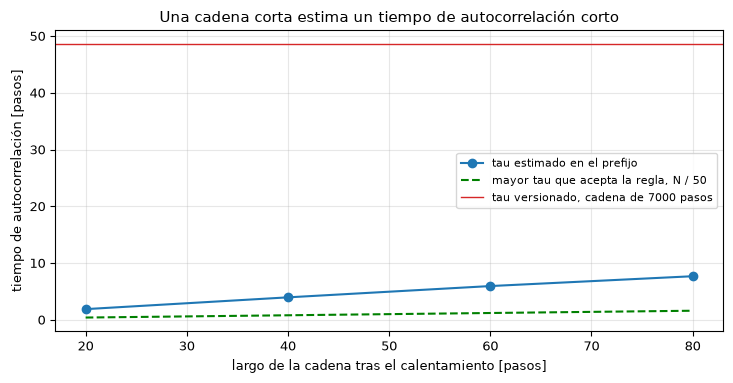

In [15]:
# El tiempo de autocorrelación estimado en prefijos crecientes de la cadena en vivo de los diez, en pasos
prefixes = [10, 20, 30, steps_kept]
tau_prefix = []
for n in prefixes:
    estimate = autocorr.integrated_time(chains[:n], tol=0, quiet=True) * all_cfg.thin
    tau_prefix.append(float(np.nanmax(estimate)))
lengths = np.array(prefixes) * all_cfg.thin
for n_steps, t in zip(lengths, tau_prefix):
    print(f"prefijo de {n_steps:3d} pasos: tau estimado {t:5.1f} pasos |",
          f"la regla acepta a lo más {n_steps / 50:4.1f}")
print("tau versionado de los diez:", round(folds["all"]["tau_max"], 1), "pasos")
fig, ax = plt.subplots()
ax.plot(lengths, tau_prefix, "o-", label="tau estimado en el prefijo")
ax.plot(lengths, lengths / 50, "g--", label="mayor tau que acepta la regla, N / 50")
ax.axhline(folds["all"]["tau_max"], color="tab:red", lw=1, label="tau versionado, cadena de 7000 pasos")
ax.set_xlabel("largo de la cadena tras el calentamiento [pasos]")
ax.set_ylabel("tiempo de autocorrelación [pasos]")
ax.set_title("Una cadena corta estima un tiempo de autocorrelación corto")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La estimación crece con el prefijo: mientras más largo el tramo de cadena que ve el estimador, más larga la autocorrelación que encuentra, y con ningún largo de la corrida en vivo se acerca a los 48,6 pasos versionados. El estimador solo puede ver correlaciones más cortas que la ventana que se le da, y una ventana de unas decenas de pasos no puede contener una correlación de cincuenta; la estimación queda entonces acotada por la cadena, no por la posterior. La línea segmentada hace visible la consecuencia: todo prefijo queda sobre la recta $N/50$, así que la regla rechaza correctamente a cada uno, pero el margen con que los rechaza queda subestimado, porque el $\hat\tau$ verdadero es la línea roja. Un lector que acorta la cadena para ahorrar tiempo y luego confía en el $\hat\tau$ de la propia cadena creerá que la cadena está más cerca de converger de lo que está; el remedio es el que usa el precálculo, una cadena lo bastante larga para que la estimación deje de crecer.

### Úsalo con tus propios datos: una calibración de tu propia tabla de muestreos

`fit_inline` recibe un diccionario simple: las cuatro columnas medidas de los muestreos (`css`, `f80`, `tph`, `kW`), el índice del muestreo a retener o `None` para usarlos todos, una semilla, y un `Config` con los caminantes, los pasos, el calentamiento, el raleo y los sorteos predictivos por muestra. Un lector con una tabla propia, en las cinco columnas de `data/examples/hp500-surveys.csv`, la lee con `read_surveys` y construye el diccionario desde ella; aquí la reemplaza la tabla versionada, leída desde su ruta. La celda corre una calibración deliberadamente diminuta con todos los muestreos, 40 pasos, para mostrar la llamada y lo que devuelve, e imprime a su lado la configuración del precálculo. Qué mirar antes de usar un resultado: `converged` verdadero, la cadena sobre $\hat\tau$ en o sobre 50 (y estable al alargar la cadena), una fracción de aceptación bien lejos de cero, y el criterio de descarte del documento retenido, notebook 03. La calibración completa con sus diez pliegues es `cb.build`, que escribe el contrato `hp500-crusherbayes`; los bloques del documento versionado se listan al final.

In [16]:
# Una calibración de una tabla de muestreos (la versionada en lugar de la suya), diminuta, junto al precálculo
table = read_surveys(ROOT / "data" / "examples" / "hp500-surveys.csv").accepted
mine = {"css": [s.css_mm for s in table], "f80": [s.f80_mm for s in table], "tph": [s.feed_tph for s in table],
        "kW": [s.power_kw for s in table], "held": None, "seed": 7}
tiny = cb.Config(walkers=20, steps=40, burn=10, thin=2, draws=10)
quick = cb.fit_inline(dict(mine, config=tiny.__dict__))
print("claves devueltas:", sorted(quick))
print(f"convergió {quick['converged']} | cadena sobre tau {quick['ratio']:.1f} | aceptación {quick['acceptance']:.2f}",
      f"| muestras retenidas {quick['samples']}")
print("configuración del precálculo:", {k: meth[k] for k in ("walkers", "steps", "burn_in_steps", "thin")})
print("bloques del documento versionado:", sorted(committed))

claves devueltas: ['acceptance', 'converged', 'd_samples', 'held', 'post_burn_steps', 'ratio', 'samples', 'tau_max', 'theta']
convergió False | cadena sobre tau 8.9 | aceptación 0.44 | muestras retenidas 300
configuración del precálculo: {'walkers': 20, 'steps': 7000, 'burn_in_steps': 1000, 'thin': 10}
bloques del documento versionado: ['comparators', 'comparators_note', 'contraction', 'contraction_note', 'convergence', 'engine_version', 'inputs_sha256', 'kill_criterion', 'loo', 'method', 'n', 'priors', 'schema', 'seed', 'source']


La corrida diminuta devuelve las mismas claves que los pliegues de arriba más los escalares retenidos y los sorteos de discrepancia, se informa como no convergida, como debe una cadena de 40 pasos, y conserva unos cientos de muestras; la configuración del precálculo impresa a su lado es la que converge, 20 caminantes y 7000 pasos con un calentamiento de 1000. Una calibración completa con ese largo, diez pliegues y el ajuste con todos los muestreos, la corre el precálculo en todos los núcleos, y por eso vive en el pipeline y no en un notebook. El documento versionado lleva el método, las a priori, la convergencia de cada posterior, las predicciones retenidas, los comparadores y la tabla de contracción, y el criterio de descarte aplicado tal como está escrito: un lector que calibre una tabla propia debería leer su resultado en ese orden, y detenerse en el primer bloque que falle.

## Resultados

**Respuesta:** una cadena del tamaño de un notebook muestra cómo funciona el muestreador pero no puede reemplazar a la versionada, que sí converge. El pliegue en vivo del muestreo 4 corrió 200 pasos y midió su propio tiempo de autocorrelación en 11,8 pasos, lo que hace su cadena de 11,8 tiempos de autocorrelación según su propia cuenta, bajo los 50 que exige el pipeline. El pliegue versionado del mismo muestreo, 7000 pasos, tiene un tiempo de autocorrelación de 84,8 pasos, 7,2 veces la estimación en vivo, así que la cadena en vivo mide en realidad 1,7 tiempos de autocorrelación: una cadena corta favorece a su propio diagnóstico. La cadena versionada mide 70,7 veces su tiempo de autocorrelación, y las 11 distribuciones a posteriori versionadas pasan, de 70,7 a 125,0 veces. Tampoco puede una cadena corta ordenar los parámetros según cuánto los mueven los datos: sus razones de contracción no ordenan los escalares como las versionadas (correlación de rangos -0,24 con los ocho escalares, -0,86 sin la base de capacidad), porque sus caminantes no terminan de extenderse. Lo que muestra es el mecanismo; la contracción (la base de capacidad en 0,45 de su a priori, `k1_scale`, `k2_scale`, `k3` y `t10_shift_pct` en 0,96 a 1,03) y los intervalos predictivos se leen del documento versionado, y el notebook dice qué números son en vivo.

## Resumen

La calibración es un muestreador de conjunto sobre diez dimensiones alrededor de un motor de caja negra, con la discrepancia integrada de forma exacta. Corrido en vivo sobre un pliegue muestra cómo funciona la maquinaria y cuán larga es la cadena de este problema en tiempos de autocorrelación, y que la estimación de ese largo que hace una cadena corta no es confiable; también muestra por qué existe el diagnóstico, pues una cadena corta parece plausible antes de haber convergido. El notebook siguiente deja la exploración por MCMC y mide la afirmación del método en los diez muestreos retenidos, incluso donde no gana.

La estimación de autocorrelación de una cadena corta crece con cada paso que se le da, por eso la regla necesita una cadena larga, y la misma llamada calibra la tabla propia de un lector cuando sus cuatro columnas están en un diccionario.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution: easy Bayesian computing for real parameter spaces, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9
- Goodman, J., Weare, J. (2010), Ensemble samplers with affine invariance, Communications in Applied Mathematics and Computational Science 5(1), 65-80. https://doi.org/10.2140/camcos.2010.5.65
- Foreman-Mackey, D., Hogg, D. W., Lang, D., Goodman, J. (2013), emcee: The MCMC Hammer, Publications of the Astronomical Society of the Pacific 125(925), 306-312. https://doi.org/10.1086/670067